# Pac-Man com fantasmas que mudam de lugar

Mesmo Q-learning do outro notebook, mas em **rodadas**. A cada rodada o Pac-Man treina até conseguir chegar na cereja **E**. Quando consegue, os fantasmas **T** mudam de posição e ele precisa descobrir um novo caminho (a Q-table é mantida, então ele reaproveita o que sabe e corrige o que mudou).

In [6]:
import numpy as np
import random
from collections import deque
import matplotlib.pyplot as plt

## 1. Labirinto e ambiente

In [7]:
BASE = [
    "S..#....#...T...",
    ".#.#.T#.#.#.###.",
    ".#...#..#.#...#.",
    ".T##.#.##.###.#.",
    "...#.#.T..#...#.",
    "#T.#T#.####.###.",
    "...T...#....#...",
    ".#T..#.#.##.#.#.",
    ".#.###.#.#T.#.#.",
    ".#.....#.#..#.#.",
    ".####T.#.####.#.",
    ".....T..........",
    ".######.######T.",
    ".#...T..#.....#.",
    ".#.#####.#.##.#.",
    "...T....T#...#.E",
]
maze = [list(r) for r in BASE]          # mutável: os fantasmas (T) mudam entre rodadas
N_ROWS, N_COLS = len(maze), len(maze[0])
N_GHOSTS = sum(r.count("T") for r in maze)
ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
ACTION_NAME = {0: "↑", 1: "↓", 2: "←", 3: "→"}
PELLET_BONUS = 3

def find(char):
    return next((i, r.index(char)) for i, r in enumerate(maze) if char in r)

START, EXIT = find("S"), find("E")


def step(state, action, eaten):
    di, dj = ACTIONS[action]
    i, j = state[0] + di, state[1] + dj
    if not (0 <= i < N_ROWS and 0 <= j < N_COLS) or maze[i][j] == "#":
        return state, -5, False
    cell = maze[i][j]
    if cell == "T":
        return (i, j), -100, True
    if cell == "E":
        return (i, j), +100, True
    if cell == "." and (i, j) not in eaten:
        eaten.add((i, j))
        return (i, j), -1 + PELLET_BONUS, False
    return (i, j), -1, False

## 2. Mudar os fantasmas
Os `T` vão para células que **não** tinham fantasma na rodada anterior. O sorteio se repete até existir pelo menos um caminho livre de `S` até `E` (senão o labirinto seria impossível).

In [8]:
def solvable():
    seen, q = {START}, deque([START])
    while q:
        i, j = q.popleft()
        if (i, j) == EXIT:
            return True
        for di, dj in ACTIONS.values():
            n = (i + di, j + dj)
            if 0 <= n[0] < N_ROWS and 0 <= n[1] < N_COLS and n not in seen and maze[n[0]][n[1]] not in "#T":
                seen.add(n); q.append(n)
    return False


def move_ghosts(rng):
    old = {(i, j) for i in range(N_ROWS) for j in range(N_COLS) if maze[i][j] == "T"}
    for i, j in old:
        maze[i][j] = "."
    free = [(i, j) for i in range(N_ROWS) for j in range(N_COLS) if maze[i][j] == "." and (i, j) not in old]
    while True:
        new = rng.sample(free, N_GHOSTS)
        for i, j in new:
            maze[i][j] = "T"
        if solvable():
            return old
        for i, j in new:
            maze[i][j] = "."

## 3. Treino por rodadas
- `CHECK` — de quantos em quantos episódios testamos o walker sem exploração; se ele sai vivo, a rodada acaba.
- `EPS_FIRST` / `EPS_NEXT` — exploração inicial na 1ª rodada e nas seguintes (menor, porque ele já sabe algo).
- `MAX_EP` — limite de episódios por rodada.

In [9]:
alpha, gamma = 0.2, 0.5
EPS_FIRST, EPS_NEXT, EPS_MIN, DECAY = 1.0, 0.4, 0.01, 0.998
MAX_STEPS, MAX_EP, CHECK = 400, 5000, 20
N_ROUNDS, SEED = 6, 42


def run_greedy(Q):
    state, path, eaten = START, [START], set()
    for _ in range(MAX_STEPS):
        state, _, done = step(state, int(np.argmax(Q[state])), eaten)
        path.append(state)
        if done:
            return path, state == EXIT
    return path, False


def train_round(Q, eps):
    for ep in range(1, MAX_EP + 1):
        state, eaten = START, set()
        for _ in range(MAX_STEPS):
            a = random.randint(0, 3) if random.random() < eps else int(np.argmax(Q[state]))
            new, r, done = step(state, a, eaten)
            target = r if done else r + gamma * np.max(Q[new])
            Q[state][a] += alpha * (target - Q[state][a])
            state = new
            if done:
                break
        eps = max(EPS_MIN, eps * DECAY)
        if ep % CHECK == 0:
            path, ok = run_greedy(Q)
            if ok:
                return ep, path
    return None, run_greedy(Q)[0]


random.seed(SEED); np.random.seed(SEED)
rng = random.Random(SEED)
Q = np.zeros((N_ROWS, N_COLS, 4))
rounds = []   # (rodada, labirinto, caminho, episódios para passar)
tries = {}    # rodada -> (labirinto, caminho, resultado) do walker ANTES de treinar no arranjo novo

for r in range(1, N_ROUNDS + 1):
    n, path = train_round(Q, EPS_FIRST if r == 1 else EPS_NEXT)
    rounds.append((r, [row[:] for row in maze], path, n))
    if n is None:
        print(f"Rodada {r}: não passou em {MAX_EP} episódios. Parando."); break
    print(f"Rodada {r}: passou após {n} episódios ({len(path) - 1} passos)")
    if r < N_ROUNDS:
        for gi, gj in move_ghosts(rng):          # esquece o medo de onde havia fantasma
            for a, (di, dj) in ACTIONS.items():
                if 0 <= gi - di < N_ROWS and 0 <= gj - dj < N_COLS:
                    Q[gi - di, gj - dj, a] = 0
        path0, ok0 = run_greedy(Q)           # o que o walker velho faz no arranjo novo?
        tries[r + 1] = ([row[:] for row in maze], path0,
                        "exit" if ok0 else "died" if maze[path0[-1][0]][path0[-1][1]] == "T" else "lost")
        print(f"   -> fantasmas mudaram de lugar (sem treinar: {tries[r + 1][2]})")

Rodada 1: passou após 840 episódios (46 passos)
   -> fantasmas mudaram de lugar (sem treinar: died)
Rodada 2: passou após 160 episódios (30 passos)
   -> fantasmas mudaram de lugar (sem treinar: died)
Rodada 3: passou após 20 episódios (32 passos)
   -> fantasmas mudaram de lugar (sem treinar: died)
Rodada 4: passou após 100 episódios (42 passos)
   -> fantasmas mudaram de lugar (sem treinar: died)
Rodada 5: passou após 20 episódios (32 passos)
   -> fantasmas mudaram de lugar (sem treinar: died)
Rodada 6: passou após 380 episódios (44 passos)


## 4. Resultados

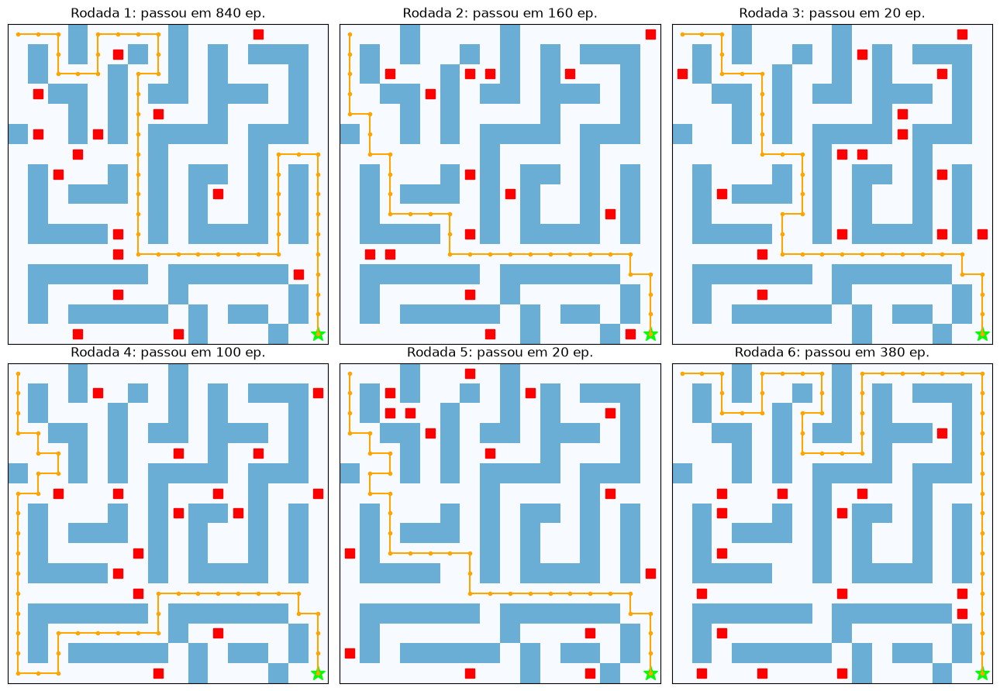

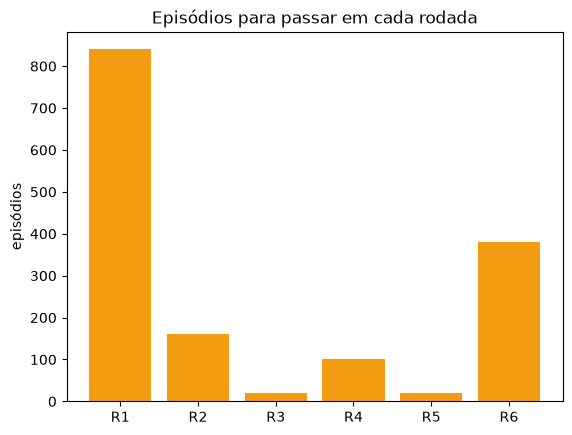

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(13, 9))
for ax, (r, mz, path, n) in zip(axs.flat, rounds):
    ax.set_facecolor("black")
    ax.imshow([[1 if c == "#" else 0 for c in row] for row in mz], cmap="Blues", vmin=0, vmax=2)
    for i, row in enumerate(mz):
        for j, c in enumerate(row):
            if c == "T": ax.plot(j, i, "s", color="red", ms=9)
            if c == "E": ax.plot(j, i, "*", color="lime", ms=14)
    ys, xs = zip(*path)
    ax.plot(xs, ys, "-o", color="orange", ms=3)
    ax.set_title(f"Rodada {r}: " + (f"passou em {n} ep." if n else "NÃO passou"))
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

ok = [(r, n) for r, _, _, n in rounds if n]
plt.bar([f"R{r}" for r, _ in ok], [n for _, n in ok], color="#f39c12")
plt.title("Episódios para passar em cada rodada"); plt.ylabel("episódios"); plt.show()

## 5. Animação
Igual ao notebook `labirinto_rl_video`: fundo preto, paredes azuis, bolinhas que somem quando comidas, fantasmas coloridos e cereja. Cada rodada mostra o caminho do Pac-Man já treinado naquele arranjo de fantasmas, e os fantasmas mudam de lugar na troca de rodada.

In [11]:
from matplotlib import animation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle, Wedge
from IPython.display import HTML

GHOST_COLORS = ["#ff0000", "#ffb8ff", "#00ffff", "#ffb852"]   # Blinky, Pinky, Inky, Clyde


def draw_ghost(ax, x, y, col):
    parts = [ax.add_patch(Circle((x, y - .05), .33, fc=col, ec="none", zorder=3)),
             ax.add_patch(Rectangle((x - .33, y - .05), .66, .36, fc=col, ec="none", zorder=3))]
    for dx in (-.12, .12):
        parts.append(ax.add_patch(Circle((x + dx, y - .1), .09, fc="white", ec="none", zorder=4)))
        parts.append(ax.add_patch(Circle((x + dx + .03, y - .1), .04, fc="#1a1aa6", ec="none", zorder=4)))
    return parts


def make_video(rounds, max_steps=60, pause=8, fps=6, filename="walker_rodadas"):
    # clips: (título, labirinto, caminho, resultado); antes de cada rodada nova vem a tentativa sem treino
    clips = []
    for r, mz, path, n in rounds:
        if r in tries:
            clips.append((f"Rodada {r}: fantasmas mudaram, ainda sem treinar", *tries[r]))
        clips.append((f"Rodada {r}" + (f"  (aprendeu em {n} ep.)" if n else ""), mz, path, "exit" if n else "lost"))
    frame_list = []
    for k, (_, _, path, _) in enumerate(clips):
        n = min(len(path), max_steps)
        frame_list += [(k, p) for p in range(n)] + [(k, n - 1)] * pause

    fig, ax = plt.subplots(figsize=(6.5, 7))
    ax.set_facecolor("black")
    walls = [[1 if c == "#" else 0 for c in row] for row in rounds[0][1]]
    ax.imshow(walls, cmap=ListedColormap(["#000000", "#1a1aa6"]), vmin=0, vmax=1)

    # bolinha em toda célula que é '.' em alguma rodada (onde havia fantasma, volta a ter bolinha)
    pellets = {(i, j): ax.add_patch(Circle((j, i), .09, fc="#ffd9a0", ec="none", zorder=2))
               for i in range(N_ROWS) for j in range(N_COLS)
               if any(mz[i][j] == "." for _, mz, _, _ in clips)}
    ghosts = [[draw_ghost(ax, j, i, GHOST_COLORS[g % 4])
               for g, (i, j) in enumerate((i, j) for i in range(N_ROWS) for j in range(N_COLS) if mz[i][j] == "T")]
              for _, mz, _, _ in clips]
    ei, ej = EXIT
    for dx in (-.15, .15):
        ax.add_patch(Circle((ej + dx, ei + .15), .15, fc="#e60000", ec="none", zorder=3))
    ax.plot([ej - .15, ej, ej + .15], [ei, ei - .3, ei], color="#2ecc71", lw=2, zorder=3)
    ax.set_xticks([]); ax.set_yticks([])

    trail, = ax.plot([], [], "-", color="#f39c12", lw=2, alpha=.6)
    walker = Wedge((0, 0), .4, 30, 330, fc="#f1c40f", ec="black", lw=1.5, zorder=5)
    ax.add_patch(walker)
    title = ax.set_title("", fontsize=10)
    banner = ax.text(N_COLS / 2 - .5, N_ROWS / 2 - .5, "", ha="center", va="center", fontsize=34, weight="bold")
    angle = [0]

    def update(q):
        k, p = frame_list[q]
        name, mz, path, result = clips[k]
        ys, xs = zip(*path[:p + 1])
        trail.set_data(xs, ys)
        visited = set(path[:p + 1])
        for (i, j), b in pellets.items():
            b.set_visible(mz[i][j] == "." and (i, j) not in visited)
        for g, parts in enumerate(ghosts):
            for grp in parts:
                for a in grp:
                    a.set_visible(g == k)
        if p > 0 and (xs[-1], ys[-1]) != (xs[-2], ys[-2]):
            angle[0] = np.degrees(np.arctan2(ys[-1] - ys[-2], xs[-1] - xs[-2]))
        mouth = 35 if p % 2 == 0 else 5
        walker.set_center((xs[-1], ys[-1]))
        walker.set_theta1(angle[0] + mouth); walker.set_theta2(angle[0] + 360 - mouth)
        title.set_text(f"{name}\npasso {p}")
        if p == min(len(path), max_steps) - 1:
            txt, col = {"exit": ("SAIU VIVO!", "#27ae60"), "died": ("MORREU!", "#c0392b")}.get(result, ("PERDIDO", "#7f8c8d"))
            banner.set_text(txt); banner.set_color(col)
        else:
            banner.set_text("")
        return trail, walker, title, banner

    anim = animation.FuncAnimation(fig, update, frames=len(frame_list), interval=1000 / fps, blit=False)
    plt.close(fig)
    if animation.writers.is_available("ffmpeg"):
        anim.save(filename + ".mp4", writer=animation.FFMpegWriter(fps=fps))
        print(f"Vídeo salvo: {filename}.mp4")
    else:
        anim.save(filename + ".gif", writer=animation.PillowWriter(fps=fps))
        print(f"Vídeo salvo: {filename}.gif  (instale ffmpeg para gerar .mp4)")
    return anim


anim = make_video(rounds)
HTML(anim.to_jshtml())        # player com play/pausa dentro do notebook

Vídeo salvo: walker_rodadas.gif  (instale ffmpeg para gerar .mp4)
